# Lab 2 — Music Genre Classification with CNNs

Notebook didáctico para clasificar géneros musicales a partir de mel-spectrograms. Incluye una CNN sencilla y un modelo VGG16 preentrenado. No modifica ningún archivo de `Lab1`.

**Datos esperados:** la carpeta `images_original` del dataset GTZAN, con una subcarpeta por género. En Colab puedes montar Drive o subir la carpeta; en Jupyter, indica su ruta en la siguiente sección.

## 1. Imports y configuración

Si falta alguna librería, descomenta y ejecuta la instalación. TensorFlow/Keras es la librería usada en este notebook.

In [10]:
# %pip install tensorflow scikit-learn matplotlib
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.22.0-rc0


## 2. Cargar las imágenes

Cambia `DATA_DIR` para que apunte a `images_original`. Se separan las rutas de forma estratificada: 80% para desarrollo y 20% para test. La validación se extrae únicamente del conjunto de desarrollo.

In [11]:
# Ejemplo Colab: '/content/drive/MyDrive/GTZAN/images_original'
DATA_DIR = 'Data/images_original'  # Cambia esta ruta según dónde estén los datos
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f'No encuentro {DATA_DIR}. Cambia DATA_DIR para apuntar a images_original.')

class_names = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
extensions = ('.png', '.jpg', '.jpeg', '.bmp')
paths, labels = [], []
for label, genre in enumerate(class_names):
    folder = os.path.join(DATA_DIR, genre)
    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith(extensions):
            paths.append(os.path.join(folder, filename))
            labels.append(label)

paths = np.array(paths)
labels = np.array(labels)
print('Géneros:', class_names)
print('Total de imágenes:', len(paths))
if len(paths) == 0:
    raise ValueError('No se han encontrado imágenes. Comprueba la estructura de carpetas.')

train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels
)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels, test_size=0.20, random_state=SEED, stratify=train_labels
)
print(f'Train: {len(train_paths)} | Validation: {len(val_paths)} | Test: {len(test_paths)}')

Géneros: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Total de imágenes: 999
Train: 639 | Validation: 160 | Test: 200


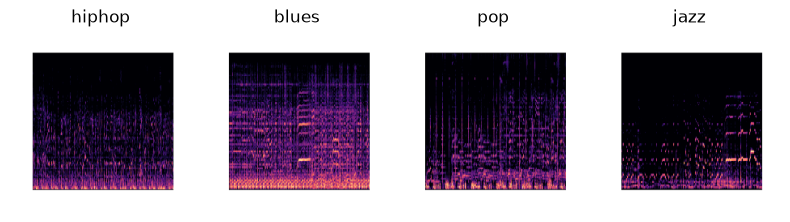

In [12]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

for images, labels_batch in train_ds.take(1):
    plt.figure(figsize=(8, 4))
    for i in range(min(4, len(images))):
        plt.subplot(1, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels_batch[i])])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## 3. Task 1 — CNN sencilla y experimentos de mejora

Partimos de la CNN del laboratorio (dos convoluciones, dos max pooling y Dense(1024)). Conservamos esa arquitectura como **baseline** y comparamos una segunda configuración regularizada. Los comentarios del código explican cada cambio.

- **Baseline:** Dropout desactivado, Dense(1024), Adam con learning rate 0.001 y sin BatchNormalization.
- **Modelo mejorado:** Dropout(0.3), Dense(256), BatchNormalization y learning rate 0.0001. Son cambios conjuntos: la comparación mide su efecto combinado, **no** el efecto aislado de cada uno.
- Ambos usan hasta 20 épocas con EarlyStopping, y se elige el modelo por **validation accuracy**. El test se reserva para la evaluación final.

**Importante:** el conjunto de datos contiene 639 imágenes de entrenamiento; si hay varios espectrogramas de una misma canción, hay que dividir por canción para evitar fugas de información. Esta versión mantiene la partición existente por imagen.

In [13]:
# Este adaptador conserva el nombre 'filter_size' usado en la referencia del lab.
# Internamente Keras exige 'kernel_size'; ambos representan el tamaño del filtro.
class Conv2DWithFilterSize(tf.keras.layers.Conv2D):
    def __init__(self, filters, filter_size, **kwargs):
        super().__init__(filters=filters, kernel_size=filter_size, **kwargs)


def generate_model(num_classes, dropout_rate=0.0, dense_units=1024,
                   use_batch_norm=False, learning_rate=1e-3):
    """Construye la CNN del laboratorio; los parámetros permiten comparar mejoras."""
    model = tf.keras.Sequential()
    # Input explícito: evita el warning de Keras sobre input_shape.
    model.add(tf.keras.Input(shape=(224, 224, 3)))
    # Reducir a 64x64 limita memoria y coste de Flatten + Dense.
    model.add(tf.keras.layers.Resizing(64, 64))
    # Normalizar píxeles de [0, 255] a [0, 1] facilita el aprendizaje.
    model.add(tf.keras.layers.Rescaling(1./255))

    # Dos bloques convolucionales de la arquitectura original.
    model.add(Conv2DWithFilterSize(32, filter_size=3, activation='relu'))
    if use_batch_norm:
        # NUEVO: normaliza activaciones para estabilizar el entrenamiento.
        model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))
    model.add(Conv2DWithFilterSize(64, filter_size=3, activation='relu'))
    if use_batch_norm:
        model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

    model.add(tf.keras.layers.Flatten())
    # CONFIGURABLE: 1024 neuronas reproducen el baseline; 256 reducen parámetros.
    model.add(tf.keras.layers.Dense(dense_units, activation='relu'))
    if dropout_rate > 0:
        # NUEVO: apaga aleatoriamente una fracción de activaciones SOLO al entrenar.
        # Busca reducir el overfitting; no actúa durante predict/evaluate.
        model.add(tf.keras.layers.Dropout(dropout_rate))
    model.add(tf.keras.layers.Dense(num_classes, activation='softmax'))
    # CONFIGURABLE: un learning rate menor produce pasos de optimización más pequeños.
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


num_classes = len(class_names)
# Dos configuraciones sobre exactamente los mismos train/validation/test.
# El baseline conserva la arquitectura de referencia sin regularización adicional.
configurations = {
    'Baseline': dict(dropout_rate=0.0, dense_units=1024,
                     use_batch_norm=False, learning_rate=1e-3),
    'Regularizada': dict(dropout_rate=0.3, dense_units=256,
                         use_batch_norm=True, learning_rate=1e-4),
}

cnn_runs = {}
for name, params in configurations.items():
    print(f'\\n--- Entrenando {name} ---')
    # Reiniciar la semilla permite repetir más fácilmente cada experimento.
    tf.keras.utils.set_random_seed(SEED)
    candidate = generate_model(num_classes, **params)
    # NUEVO: hasta 20 épocas; EarlyStopping detiene antes si no mejora val_accuracy.
    # restore_best_weights recupera los pesos de la mejor época de validación.
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', mode='max', patience=4,
        restore_best_weights=True
    )
    candidate_history = candidate.fit(
        train_ds, validation_data=val_ds, epochs=20,
        shuffle=False,  # tf.data.Dataset ya mezcla train_ds con .shuffle().
        callbacks=[early_stop], verbose=1
    )
    # Selección SOLO con validación: no usamos test para elegir el modelo.
    best_val = max(candidate_history.history['val_accuracy'])
    cnn_runs[name] = dict(model=candidate, history=candidate_history,
                          val_accuracy=float(best_val), params=params)
    print(f'{name}: mejor val_accuracy = {best_val:.4f}')

# Elegimos el modelo que mejor generaliza sobre el conjunto de validación.
best_name = max(cnn_runs, key=lambda name: cnn_runs[name]['val_accuracy'])
best_cnn = cnn_runs[best_name]
history = best_cnn['history']  # Mantiene compatible la gráfica original.
model = best_cnn['model']
print(f'\\nModelo seleccionado por validación: {best_name}')

# Evaluamos en test una única vez, después de elegir la configuración.
cnn_test_loss, cnn_test_accuracy = model.evaluate(test_ds, verbose=0)
print(f'CNN seleccionada — test accuracy: {cnn_test_accuracy:.4f}')

\n--- Entrenando Baseline ---
Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 244ms/step - accuracy: 0.1471 - loss: 2.3431 - val_accuracy: 0.2438 - val_loss: 2.1515
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.2817 - loss: 1.9888 - val_accuracy: 0.4187 - val_loss: 1.7368
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 207ms/step - accuracy: 0.4178 - loss: 1.7004 - val_accuracy: 0.4250 - val_loss: 1.6304
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 222ms/step - accuracy: 0.5321 - loss: 1.4359 - val_accuracy: 0.5562 - val_loss: 1.3700
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 238ms/step - accuracy: 0.5509 - loss: 1.2243 - val_accuracy: 0.4688 - val_loss: 1.4258
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 259ms/step - accuracy: 0.6698 - loss: 1.0337 - val_accuracy: 0.5188 - val_loss: 1.3713
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 209ms/step - accuracy: 0.6995 - loss: 0.8840 - val_accuracy: 0.5875 - val_loss: 1.2933
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 210ms/step - accuracy: 0.8059 - l

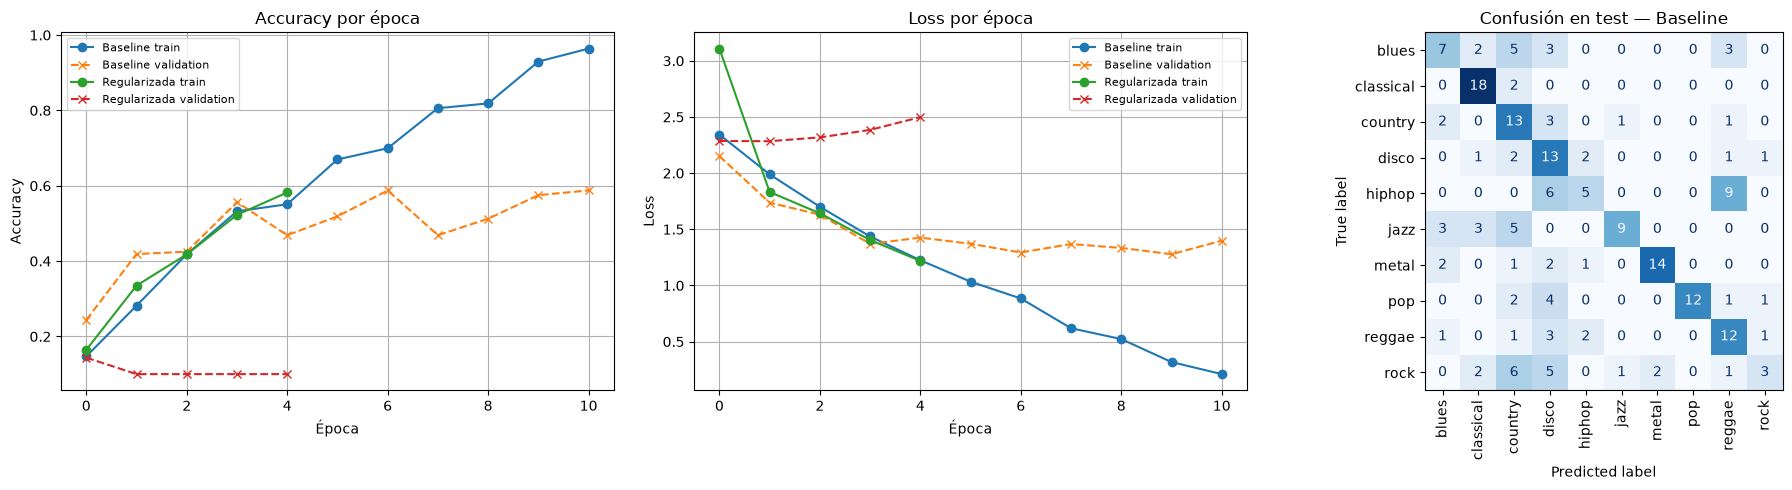

In [14]:
# NUEVO: comparar curvas de accuracy y loss ayuda a detectar overfitting.
# NUEVO: matriz de confusión al lado de las gráficas; usa el TEST reservado.
# Los ejemplos de test no se barajan (make_dataset(..., training=False)),
# por eso el orden de predicciones coincide con test_labels.
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for name, run in cnn_runs.items():
    h = run['history'].history
    axes[0].plot(h['accuracy'], marker='o', label=f'{name} train')
    axes[0].plot(h['val_accuracy'], marker='x', linestyle='--',
                 label=f'{name} validation')
    axes[1].plot(h['loss'], marker='o', label=f'{name} train')
    axes[1].plot(h['val_loss'], marker='x', linestyle='--',
                 label=f'{name} validation')

axes[0].set(title='Accuracy por época', xlabel='Época', ylabel='Accuracy')
axes[1].set(title='Loss por época', xlabel='Época', ylabel='Loss')
for ax in axes[:2]:
    ax.legend(fontsize=8)
    ax.grid(True)

# La matriz corresponde al modelo elegido por val_accuracy, no al baseline.
y_true = test_labels
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=axes[2], xticks_rotation=90, cmap='Blues', colorbar=False
)
axes[2].set_title(f'Confusión en test — {best_name}')
plt.tight_layout()
plt.show()

## 4. Task 2 — VGG16 preentrenada

Usamos VGG16 con pesos de ImageNet como extractor de características congelado y entrenamos una cabeza de clasificación. Es una adaptación sencilla de un modelo de visión a imágenes de espectrogramas.

In [ ]:
base = tf.keras.applications.VGG16(
    weights='imagenet', include_top=False, input_shape=(224, 224, 3)
)
base.trainable = False


In [ ]:
inputs = tf.keras.Input(shape=(224, 224, 3))

# Augmentation: the input is still in the 0–255 range.
x = tf.keras.layers.RandomTranslation(0.05, 0.05)(inputs)
x = tf.keras.layers.RandomZoom(0.1)(x)
x = tf.keras.layers.RandomContrast(0.1)(x)

x = tf.keras.applications.vgg16.preprocess_input(x)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4)
)(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(
    num_classes, activation="softmax"
)(x)

vgg_model = tf.keras.Model(inputs, outputs)

In [ ]:
vgg_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
vgg_history = vgg_model.fit(
    train_ds, validation_data=val_ds, epochs=5, shuffle=False,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True)]
)
vgg_test_loss, vgg_test_accuracy = vgg_model.evaluate(test_ds, verbose=0)
print(f'VGG16 — test accuracy: {vgg_test_accuracy:.4f}')

## 5. Resultados y comparación

La CNN seleccionada se elige por **validation accuracy**, sin mirar el test. El test se utiliza después para evaluar el modelo seleccionado y compararlo con VGG16. El baseline y la CNN regularizada difieren en varios hiperparámetros a la vez; para atribuir una mejora a un cambio concreto habría que realizar una ablación (modificar un parámetro por experimento).

In [ ]:
# Resumen de las dos configuraciones de Task 1: la selección usa validación.
print('Task 1 — comparación en validación')
for name, run in cnn_runs.items():
    print(f"{name}: val_accuracy={run['val_accuracy']:.4f} | {run['params']}")
print(f'Modelo seleccionado: {best_name}')

# Comparación final en test (misma partición reservada para ambas arquitecturas).
results = [
    (f'CNN {best_name}', str(best_cnn['params']), float(cnn_test_accuracy)),
    ('VGG16 congelada', 'ImageNet + cabeza densa', float(vgg_test_accuracy)),
]
for name, config, accuracy in results:
    print(f'{name}: test_accuracy={accuracy:.4f} | {config}')

# Matriz de confusión ya mostrada junto a las curvas en Task 1.
# Este informe detalla precision, recall y F1 de cada género en el TEST.
print('\\nInforme de clasificación — CNN seleccionada:')
print(classification_report(y_true, y_pred, labels=range(num_classes),
                            target_names=class_names, zero_division=0))

## 6. Discusión y comparación con Lab 1

Completa esta sección después de ejecutar el notebook. Compara la accuracy de test de la CNN definida por `generate_model()` y VGG16 con los resultados de Lab 1 obtenidos usando descriptores extraídos manualmente. Asegúrate de comparar métricas calculadas sobre particiones equivalentes; si las particiones o los datos no coinciden, indícalo. Comenta brevemente el coste de entrenamiento y los posibles errores de clasificación.

## Conclusión

Este laboratorio permite comparar la CNN de la función `generate_model()`, entrenada desde cero, con una VGG16 preentrenada usando mel-spectrograms como imágenes. La conclusión final debe basarse en las accuracies y matrices de confusión obtenidas al ejecutar las celdas.

## Notas de ejecución

1. Descarga o monta la carpeta `images_original` y ajusta `DATA_DIR`.
2. Ejecuta las celdas en orden. Task 1 entrena dos CNN y puede tardar más que antes.
3. Task 1 elige la mejor CNN con validación y solo después la evalúa en test.
4. Task 2 sigue utilizando VGG16 y descarga sus pesos si no están disponibles.

**Warnings:** se declara `Input(shape=...)` y se usa `shuffle=False` en `fit()` porque `train_ds` ya se mezcla. Los mensajes de CUDA/cuDNN indican falta de GPU utilizable; oneDNN/CPU son informativos, no fallos del modelo.

**Nota metodológica:** si existen varios espectrogramas de una misma canción, la partición debe hacerse por canción para evitar fugas de información. Actualmente se divide de forma estratificada por imagen.

**Interpretación:** la versión regularizada combina Dropout, menos neuronas densas, BatchNormalization y un learning rate menor. Si mejora, no puede atribuirse la diferencia a una sola técnica sin más experimentos.